# Лабораторна робота 2

**Тема:** Відображення точок на координатній площині за даними з файлу

**Виконав:** Бугайчук Василь 
**Група:** КМ-51

## Мета роботи

Розробити програмний засіб, який відображає точки на координатній площині за заданим датасетом і зберігає зображення в одному з графічних форматів.

## Завдання

1. Обрати індивідуальний [датасет](https://do.ipo.kpi.ua/mod/folder/view.php?id=277950). Номер датасета відповідає останній цифрі логіну на платформі «Сікорський» (наприклад, `km-95-019` — `DS9`).
2. Завантажити файл із датасетом. Файл у текстовому форматі містить пари цілих чисел — координати точок.
3. Написати програму, яка:
    - зчитує датасет із файлу;
    - встановлює розмір полотна **960 × 540 пікселів**;
    - відображає точки, вважаючи початком координат нижній лівий кут, а додатними напрямками осі **X** і **Y** — праворуч і вгору відповідно;
    - зберігає результат у графічному форматі.

Зчитано 48802 точок. Збережено DS7_plot.png (960 × 540 пкс).


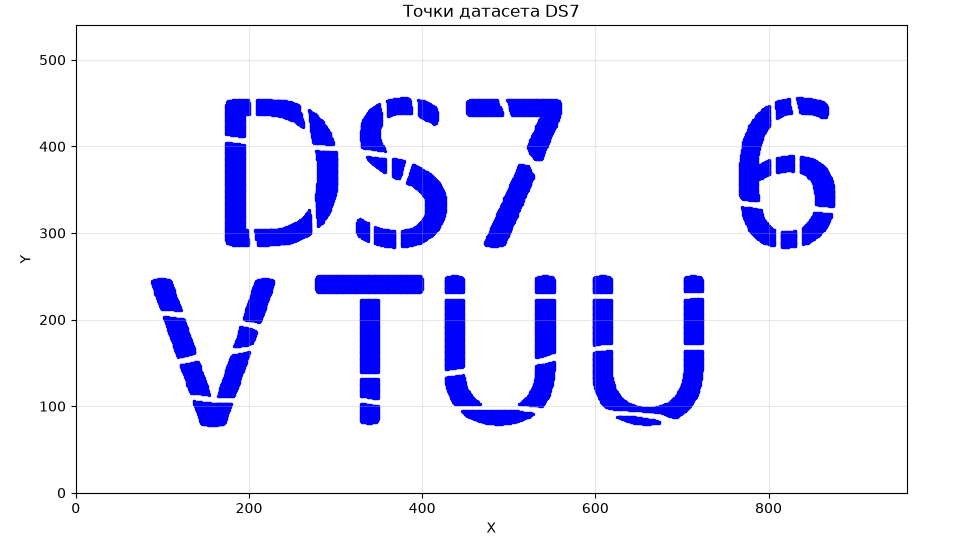

In [1]:
from pathlib import Path
import math
import matplotlib.pyplot as plt

# Підтримуємо запуск із папки лабораторної або кореня репозиторію.
root = Path.cwd()
if not (root / "лабораторна робота 2").is_dir():
    root = root.parent

input_path = root / "лабораторна робота 2" / "DS7.txt"
output_path = input_path.parent / "DS7_plot.png"
points = []
with input_path.open(encoding="utf-8") as file:
    for line in file:
        if line.strip() and not line.lstrip().startswith("#"):
            x, y = map(float, line.split())
            points.append((x, y))

fig, ax = plt.subplots(figsize=(9.6, 5.4), dpi=100, layout="constrained")
ax.scatter([x for x, y in points], [y for x, y in points], s=2, color="blue")
ax.set(xlim=(0, 960), ylim=(0, 540), xlabel="X", ylabel="Y",
       title="Точки датасета DS7")
ax.set_aspect("equal", adjustable="box")
ax.grid(True, alpha=0.3)
fig.savefig(output_path, dpi=100)
plt.show()
print(f"Зчитано {len(points)} точок. Збережено {output_path.name} (960 × 540 пкс).")




## Реалізація

Початок координат задається межами X від 0 до 960 та Y від 0 до 540. PNG зберігається без обрізання полів із розміром 960 × 540 пікселів.